<a href="https://colab.research.google.com/github/Erreenn10/pm-turi4-clustering/blob/main/praktikum9_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

def grup(n, usia, pend, skor):
    return pd.DataFrame({
        'usia': rng.normal(usia[0], usia[1], n).clip(18, 70),
        'pendapatan': rng.normal(pend[0], pend[1], n).clip(3, None),   # juta Rp/bulan
        'skor_belanja': rng.normal(skor[0], skor[1], n).clip(1, 100)
    })

df = pd.concat([
    grup(70, (24, 3), (6, 1.5),  (80, 8)),    # muda, pendapatan rendah, belanja tinggi
    grup(70, (45, 5), (22, 3),   (70, 8)),    # paruh baya, pendapatan tinggi, belanja tinggi
    grup(60, (52, 6), (12, 2.5), (25, 8)),    # lebih tua, pendapatan menengah, belanja rendah
], ignore_index=True).round(1)

print(df.describe().round(1))

        usia  pendapatan  skor_belanja
count  200.0       200.0         200.0
mean    39.8        13.3          59.5
std     12.7         7.3          25.0
min     18.1         3.4           5.7
25%     25.8         6.5          30.7
50%     43.2        12.0          70.4
75%     49.9        20.7          77.5
max     67.6        27.5          97.0


In [11]:
X_scaled = StandardScaler().fit_transform(df)

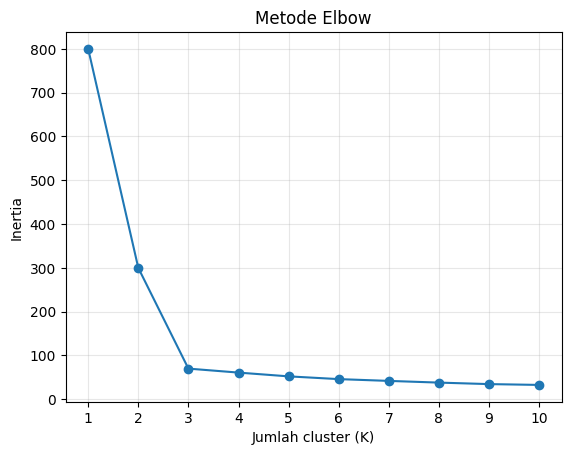

In [12]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia')
plt.title('Metode Elbow'); plt.xticks(range(1, 11)); plt.grid(alpha=.3)
plt.show()

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

sil3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette K=3 (scaled):', round(sil3, 3))

profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
print(profil)

cluster
2    70
0    70
1    60
Name: count, dtype: int64
Silhouette K=3 (scaled): 0.701
         usia  pendapatan  skor_belanja
cluster                                
0        45.1        22.1          70.2
1        51.9        11.9          23.8
2        24.2         5.8          79.5


In [8]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
sil5 = silhouette_score(X_scaled, km5.fit_predict(X_scaled))

fitur = ['usia','pendapatan','skor_belanja']
lab_ns = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(df[fitur])
sil_ns = silhouette_score(df[fitur], lab_ns)

print(f'Silhouette K=5 (scaling)      : {sil5:.3f}')
print(f'Silhouette K=3 (tanpa scaling): {sil_ns:.3f}')
print(pd.crosstab(df['cluster'], lab_ns))

Silhouette K=5 (scaling)      : 0.442
Silhouette K=3 (tanpa scaling): 0.651
col_0     0   1   2
cluster            
0        70   0   0
1         0  60   0
2         0   0  70


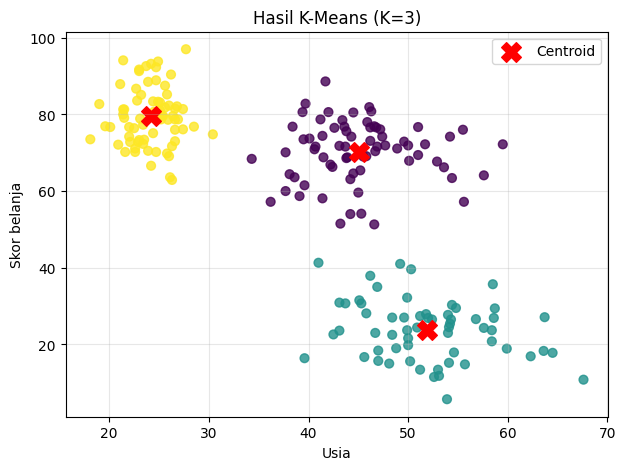

In [13]:
plt.figure(figsize=(7,5))
plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=40, alpha=.8)
cent_asli = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
plt.scatter(cent_asli[:,0], cent_asli[:,2], c='red', marker='X', s=200, label='Centroid')
plt.xlabel('Usia'); plt.ylabel('Skor belanja'); plt.title('Hasil K-Means (K=3)')
plt.legend(); plt.grid(alpha=.3); plt.show()

# Praktikum 9 - Clustering dengan K-Means



## Latihan Mandiri

**1. K=5 vs K=3**
Silhouette K=3 = 0,701 dan K=5 = 0,442, jadi K=3 lebih bagus. Datanya memang
cuma punya 3 kelompok, jadi kalau dipaksa 5, ada kelompok yang terpecah dan
batasnya jadi kabur.

**2. Tanpa scaling**
Silhouette dengan scaling 0,701, tanpa scaling 0,651. Dari crosstab, anggota
cluster-nya sama persis (70, 60, 70), jadi di data ini scaling tidak mengubah
hasil. Kemungkinan karena datanya buatan dan tiga kelompoknya sudah terpisah
jauh. Tapi skala fitur beda-beda (std usia 12,7, pendapatan 7,3, skor belanja
25,0), jadi di data asli yang kelompoknya lebih campur, scaling tetap penting.

**3. Scatter plot usia vs skor belanja**
Terlihat 3 kelompok yang jelas terpisah. Yang muda (±24 tahun) skor belanjanya
tinggi (±80), yang usia ±45 skornya ±70, dan yang paling tua (±52 tahun) skornya
rendah (±24). Tanda X merah itu centroid.

## Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**
Cuma pakai jarak. Centroid awal dipilih acak, tiap data masuk ke centroid
terdekat, lalu centroid dihitung ulang dari rata-rata anggotanya. Diulang terus
sampai anggota cluster tidak berubah lagi.

**2. Kenapa Elbow bersiku di K=3?**
Karena datanya memang terdiri dari 3 kelompok. Sampai K=3, tiap cluster baru
memisahkan kelompok yang beda, jadi inertia turun jauh. Setelah itu cluster
tambahan cuma membelah kelompok yang sudah rapat, jadi turunnya sedikit dan
grafiknya landai.

**3. Kenapa scaling penting?**
K-Means berbasis jarak, jadi fitur yang angkanya besar (di sini skor belanja)
lebih mendominasi. Kalau tidak di-scaling, cluster bisa condong ke satu fitur
saja. Di praktikum ini hasilnya kebetulan sama, tapi itu karena datanya buatan
dan kelompoknya sangat terpisah.

## Kesimpulan
Pelanggan terbagi jadi 3 segmen (Anak Muda Trendi, Premium, Hemat) dengan
silhouette 0,701. K=3 dipilih dari Elbow dan terbukti lebih baik daripada K=5
(0,442). Scaling tidak mengubah hasil di data ini, tapi tetap saya pakai karena
K-Means berbasis jarak.